In [1]:
import pandas as pd

In [2]:
df = pd.read_excel("Gap within country in europa PISA 2025.xlsx")

In [3]:
df.head()

,Country,Reading gap,SES gap,Language gap
0,Sweden,-90.40483,-0.83287,79.38037
1,Austria,-71.96289,-0.65927,75.84735
2,Belgium,-59.34997,-0.75245,66.33035
3,Bulgaria,-41.95278,-0.01690,75.65648
4,Croatia,-44.32985,-0.15874,56.58874


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country       35 non-null     str    
 1   Reading gap   35 non-null     float64
 2   SES gap       35 non-null     float64
 3   Language gap  35 non-null     float64
dtypes: float64(3), str(1)
memory usage: 1.2 KB


In [5]:
df['reading disadvantage'] =-df['Reading gap']
df["SES disadvantage"] = -df["SES gap"]

In [6]:
df.head()

,Country,Reading gap,SES gap,Language gap,reading disadvantage,SES disadvantage
0,Sweden,-90.40483,-0.83287,79.38037,90.40483,0.83287
1,Austria,-71.96289,-0.65927,75.84735,71.96289,0.65927
2,Belgium,-59.34997,-0.75245,66.33035,59.34997,0.75245
3,Bulgaria,-41.95278,-0.01690,75.65648,41.95278,0.01690
4,Croatia,-44.32985,-0.15874,56.58874,44.32985,0.15874


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country               35 non-null     str    
 1   Reading gap           35 non-null     float64
 2   SES gap               35 non-null     float64
 3   Language gap          35 non-null     float64
 4   reading disadvantage  35 non-null     float64
 5   SES disadvantage      35 non-null     float64
dtypes: float64(5), str(1)
memory usage: 1.8 KB


In [8]:
df.isna().sum()

Country                 0
Reading gap             0
SES gap                 0
Language gap            0
reading disadvantage    0
SES disadvantage        0
dtype: int64

In [9]:
df[["reading disadvantage","SES disadvantage", "Language gap"]].corr()

,reading disadvantage,SES disadvantage,Language gap
reading disadvantage,1.000000,0.477467,0.510294
SES disadvantage,0.477467,1.000000,0.410566
Language gap,0.510294,0.410566,1.000000


In [10]:
import matplotlib.pyplot as plt

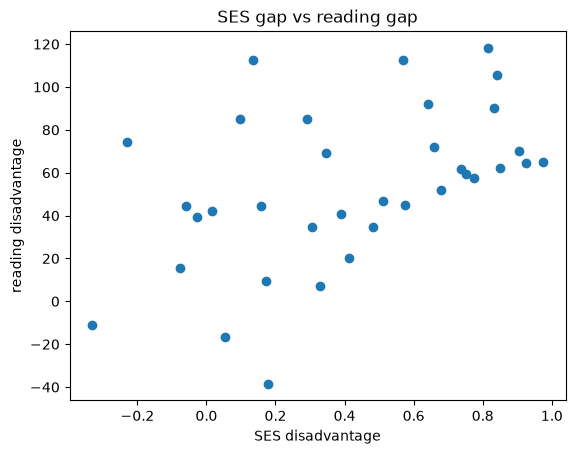

In [11]:
plt.scatter(df["SES disadvantage"], df["reading disadvantage"])
plt.xlabel("SES disadvantage")
plt.ylabel("reading disadvantage")
plt.title("SES gap vs reading gap")
plt.show()

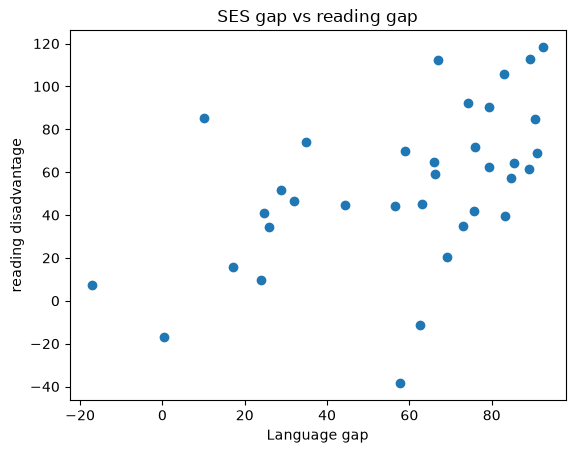

In [12]:
plt.scatter(df["Language gap"], df["reading disadvantage"])
plt.xlabel("Language gap")
plt.ylabel("reading disadvantage")
plt.title("SES gap vs reading gap")
plt.show()

In [15]:
%matplotlib widget
import matplotlib.pyplot as plt
import mplcursors

In [16]:
import numpy as np

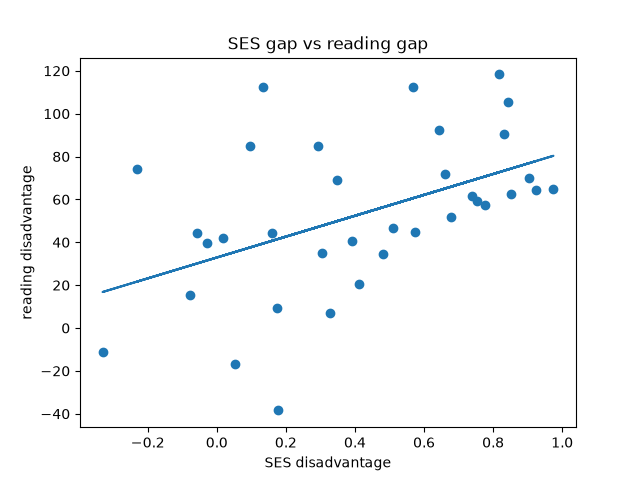

In [17]:
x = df["SES disadvantage"]
y = df["reading disadvantage"]
fig, ax = plt.subplots()
scatter = ax.scatter(df["SES disadvantage"], df["reading disadvantage"])
m, b = np.polyfit(x, y, 1)
ax.plot(x, m*x + b)
ax.set_xlabel("SES disadvantage")
ax.set_ylabel("reading disadvantage")
ax.set_title("SES gap vs reading gap")
cursor =mplcursors.cursor(scatter, hover=False)
@cursor.connect("add")
def on_add(sel):
    country = df.iloc[sel.index]["Country"]
    sel.annotation.set_text(country)
plt.show()

In [18]:
import matplotlib
print(matplotlib.get_backend())

widget


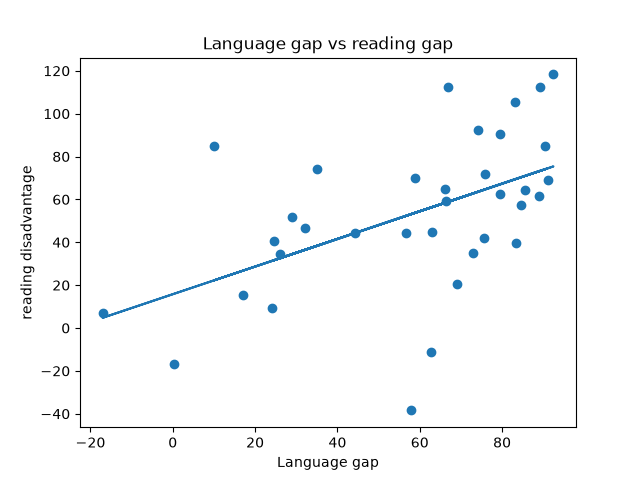

In [19]:
x = df["Language gap"]
y = df["reading disadvantage"]
fig, ax1 = plt.subplots()
scatter = ax1.scatter(df["Language gap"], df["reading disadvantage"])
m,b = np.polyfit(x, y, 1)
ax1.plot(x, m*x +b)
ax1.set_xlabel("Language gap")
ax1.set_ylabel("reading disadvantage")
ax1.set_title("Language gap vs reading gap")
cursor =mplcursors.cursor(scatter, hover=False)
@cursor.connect("add")
def on_add(sel):
    country = df.iloc[sel.index]["Country"]
    sel.annotation.set_text(country)
plt.show()

In [21]:
import statsmodels.api as sm

In [22]:
X = df[["SES disadvantage","Language gap"]]
y = df["reading disadvantage"]
X = sm.add_constant(X)
model = sm.OLS(y,X).fit()
print(model.summary())

                             OLS Regression Results                             
Dep. Variable:     reading disadvantage   R-squared:                       0.347
Model:                              OLS   Adj. R-squared:                  0.306
Method:                   Least Squares   F-statistic:                     8.493
Date:                  Sat, 12 Sep 2026   Prob (F-statistic):            0.00110
Time:                          22:08:04   Log-Likelihood:                -167.93
No. Observations:                    35   AIC:                             341.9
Df Residuals:                        32   BIC:                             346.5
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               

In [23]:
df["predicted_reading_disadvantage"] = model.predict(X)

df["residual"] = (
    df["reading disadvantage"]
    - df["predicted_reading_disadvantage"]
)

In [24]:
df[df["Country"] == "Sweden"][
    ["Country",
     "reading disadvantage",
     "predicted_reading_disadvantage",
     "residual"]
]

,Country,reading disadvantage,predicted_reading_disadvantage,residual
0,Sweden,90.40483,77.007609,13.397221


In [25]:
df.sort_values("residual", ascending=False)[
    ["Country", "residual"]
]

,Country,residual
24,North Macedonia,65.453626
17,Latvia,64.413615
28,Romania,53.329910
9,Finland,39.507719
14,Iceland,35.613389
11,Germany,26.542995
12,Greece,23.869032
6,Czechia,20.352036
29,Serbia,13.486198
0,Sweden,13.397221


In [26]:
influence = model.get_influence()

df["studentized_residual"] = influence.resid_studentized_internal

In [27]:
df.sort_values(
    "studentized_residual",
    ascending=False
)[["Country", "residual", "studentized_residual"]]

,Country,residual,studentized_residual
24,North Macedonia,65.453626,2.261572
17,Latvia,64.413615,2.165492
28,Romania,53.329910,1.856730
9,Finland,39.507719,1.329134
14,Iceland,35.613389,1.211494
11,Germany,26.542995,0.898598
12,Greece,23.869032,0.794980
6,Czechia,20.352036,0.694346
29,Serbia,13.486198,0.458181
0,Sweden,13.397221,0.452514


In [29]:
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

In [30]:
cols = ["SES disadvantage", "Language gap", "reading disadvantage"]

scaled = StandardScaler().fit_transform(df[cols])

In [31]:
df_std = pd.DataFrame(
    scaled,
    columns=cols
)

In [32]:
X_std = df_std[["SES disadvantage", "Language gap"]]
y_std = df_std["reading disadvantage"]

X_std = sm.add_constant(X_std)

model_std = sm.OLS(y_std, X_std).fit()

print(model_std.summary())

                             OLS Regression Results                             
Dep. Variable:     reading disadvantage   R-squared:                       0.347
Model:                              OLS   Adj. R-squared:                  0.306
Method:                   Least Squares   F-statistic:                     8.493
Date:                  Sat, 12 Sep 2026   Prob (F-statistic):            0.00110
Time:                          22:08:06   Log-Likelihood:                -42.211
No. Observations:                    35   AIC:                             90.42
Df Residuals:                        32   BIC:                             95.09
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -9.

In [33]:
df_no3 = df[
    ~df["Country"].isin(
        ["North Macedonia", "Latvia"]
    )
]

X3 = df_no3[["SES disadvantage", "Language gap"]]
y3 = df_no3["reading disadvantage"]

X3 = sm.add_constant(X3)

model3 = sm.OLS(y3, X3).fit()

print(model3.summary())

                             OLS Regression Results                             
Dep. Variable:     reading disadvantage   R-squared:                       0.500
Model:                              OLS   Adj. R-squared:                  0.467
Method:                   Least Squares   F-statistic:                     15.01
Date:                  Sat, 12 Sep 2026   Prob (F-statistic):           3.04e-05
Time:                          22:08:06   Log-Likelihood:                -153.10
No. Observations:                    33   AIC:                             312.2
Df Residuals:                        30   BIC:                             316.7
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               

In [38]:
# MAIN MODEL FOR POST 1
# 35 European countries
# Y = reading disadvantage
# X = Language gap only
X_lang_35 = sm.add_constant(df["Language gap"])

model_lang_35 = sm.OLS(
    df["reading disadvantage"],
    X_lang_35
).fit()

print(model_lang_35.summary())

                             OLS Regression Results                             
Dep. Variable:     reading disadvantage   R-squared:                       0.260
Model:                              OLS   Adj. R-squared:                  0.238
Method:                   Least Squares   F-statistic:                     11.62
Date:                  Sat, 12 Sep 2026   Prob (F-statistic):            0.00174
Time:                          22:17:35   Log-Likelihood:                -170.10
No. Observations:                    35   AIC:                             344.2
Df Residuals:                        33   BIC:                             347.3
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           15.7774     